# ST1131 Consolidated Master Notes & Function Reference

This notebook consolidates **Topics 1 to 9** of **ST1131 (Introduction to Statistics and Statistical Computing)** into one searchable, runnable reference. Each topic starts with a **Function & Argument Summary Table** so you can quickly look up exact syntax and required inputs, followed by key concepts, exam pitfalls, and runnable examples using the course datasets in `../data/`.

### Table of Contents
1. [Master Imports & Global Pitfalls](#master-imports)
2. [Topic 1: Introduction to Python & NumPy](#topic-1)
3. [Topic 2: Exploratory Data Analysis (`pandas` & `matplotlib`)](#topic-2)
4. [Topics 3 & 4: Study Design, Confounding & Probability Foundations](#topics-3-4)
5. [Topic 5: Random Variables & Probability Distributions (`scipy.stats`)](#topic-5)
6. [Topic 6: Sampling Distributions & Central Limit Theorem (CLT)](#topic-6)
7. [Topic 7: Confidence Intervals](#topic-7)
8. [Topic 8: Hypothesis Testing](#topic-8)
9. [Topic 9: Linear Regression (`statsmodels`)](#topic-9)

---
<a id="master-imports"></a>
## Master Imports & Global Pitfalls

Copy and run the import cell below at the top of any practice or exam notebook so every tool across Topics 1–9 is ready.

> **Top 5 Exam Pitfalls to Watch Out For:**
> 1. **Never overwrite `t` or Python built-ins:** Do **not** assign variables named `t` (overwrites `scipy.stats.t`), `list`, `sum`, `min`, `max`, or `lambda` (reserved keyword — use `lam` instead). Use `t_stat` or `t_mult`.
> 2. **Standard Deviation vs Variance in `scipy` / `numpy`:** In `norm(..., loc=mu, scale=sigma)` and `np.random.normal(mu, sigma, size)`, the second argument is always the **standard deviation $\sigma = \sqrt{\sigma^2}$**, **never** the variance $\sigma^2$!
> 3. **Sample vs Population SD (`ddof`):** `np.std(x)` and `np.var(x)` default to `ddof=0` (**population**). Always pass `ddof=1` in NumPy for **sample** $s$ and $s^2$! In contrast, `pandas` `s.std()` and `s.var()` already default to `ddof=1` (**sample**).
> 4. **Discrete "At Least" Probabilities:** For integer random variables like $X \sim \text{Bin}(n, p)$, $P(X \ge 5) = P(X > 4) = 1 - P(X \le 4)$, so use `binom.sf(4, n, p)` or `1 - binom.cdf(4, n, p)` (using `5` leaves out $P(X=5)$!).
> 5. **Confidence Level vs Significance Level $\alpha$:** `norm.interval(0.95, ...)`, `t.interval(0.95, ...)`, and `result.confidence_interval(0.95)` take the **confidence level (`0.95`)**, whereas `statsmodels` `model.conf_int(alpha=0.05)` and `summary_frame(alpha=0.05)` take **`alpha = 0.05`**!

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from scipy import stats
from scipy.stats import (
    bernoulli, binom, norm, t,
    ttest_1samp, ttest_ind, ttest_rel,
    levene, shapiro, probplot
)
import statsmodels.formula.api as smf

print("All ST1131 packages imported successfully!")

All ST1131 packages imported successfully!


---
<a id="topic-1"></a>
# Topic 1: Introduction to Python & NumPy

## Summary of Functions & Arguments (Topic 1)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `len(x)` | `x`: list, string, 1D array, `Series`, or `DataFrame` | Number of elements (for a `DataFrame` or 2D array, returns number of **rows**) |
| `sorted(iterable, reverse=False)` | `iterable`: list/sequence to sort<br>`reverse`: `False` = ascending (default), `True` = descending | Returns a **new** sorted list without modifying the original |
| `round(number, ndigits=None)` | `number`: float value (use `np.round(arr, k)` for arrays)<br>`ndigits`: decimal places (omit for nearest `int`) | Rounds number to `ndigits` decimal places |
| `int(x)`, `float(x)`, `str(x)`, `bool(x)` | `x`: value to convert | Type casting (`int(3.9)` truncates toward zero $\to$ `3`; `bool(0)` $\to$ `False`, non-zero/non-empty string $\to$ `True`) |
| `lst[start:end]` | `start`: starting index (`0`-based, **inclusive**; omit for `0`)<br>`end`: stopping index (**exclusive**; omit for end; `-1` = last item) | Slices a list. Use `new_lst = old_lst[:]` to copy a list safely without shared references |
| `lst.append(val)` | `val`: single element to add at the end | Mutates `lst` in-place (returns `None`). Use `lst1 + lst2` to concatenate two lists |
| `lst.remove(val)` | `val`: exact value to delete (removes **first** match only) | Mutates `lst` in-place. Use `del lst[idx]` to delete by index position |
| `lst.count(val)` / `lst.index(val)` | `val`: value (or substring for `str`) to search for | `.count(val)` returns frequency of `val`; `.index(val)` returns `0`-based index of first match |
| `np.array(object)` | `object`: list (creates 1D array) or list of lists (creates 2D array) | Creates a homogeneous NumPy `ndarray` supporting element-wise math (`arr * 5`, `arr - 1`) |
| `arr.shape` | *(Attribute — no parentheses `()`)* | Tuple of dimensions: `(n,)` for 1D array, `(rows, cols)` for 2D array |
| `arr[row, col]` | `row`: row index or slice (`start:end` or `:`)<br>`col`: column index or slice (`start:end` or `:`) | Subsets a 2D NumPy array (unlike nested lists which use `lst[row][col]`) |
| `np.arange(start, stop, step=1)` | `start`: inclusive start (default `0`)<br>`stop`: **exclusive** upper bound<br>`step`: increment size | Evenly spaced values with fixed step (e.g. `np.arange(10, 36, 5)` gives `10, 15, 20, 25, 30, 35`) |
| `np.linspace(start, stop, num=50)` | `start`: inclusive start<br>`stop`: **inclusive** end<br>`num`: how many evenly spaced points to generate | Smooth grid of `num` points across `[start, stop]` (ideal for plotting continuous PDF curves) |
| `np.mean(a, axis=None)`<br>`np.median(a, axis=None)` | `a`: array or list<br>`axis`: `None` (overall), `0` (**down columns**), `1` (**across rows**) | Arithmetic mean or median |
| `np.amin(a)` / `np.amax(a)` / `np.ptp(a)` | `a`: array or list (optional `axis=0` or `1`) | Minimum (`np.min`), maximum (`np.max`), and peak-to-peak range ($\max - \min$) |
| `np.percentile(a, q, axis=None)` | `a`: array or list<br>`q`: number in **`[0, 100]`** (e.g. `60` for 60th percentile) | Value below which `q`% of observations fall |
| `np.quantile(a, q, axis=None)` | `a`: array or list<br>`q`: proportion in **`[0, 1]`** (e.g. `0.6` for 60th percentile) | Quantile at proportion `q` (same result as `percentile` with `q * 100`) |
| `np.var(a, ddof=1, axis=None)`<br>`np.std(a, ddof=1, axis=None)` | `a`: array or list<br>`ddof`: **`0` (default) = population** ($\div N$), **`1` = sample** ($\div (n-1)$)<br>`axis`: optional `0` or `1` | Variance and standard deviation. **Always set `ddof=1` for sample statistics!** |
| `np.nanmean(a)`, `np.nanmedian(a)`,<br>`np.nanvar(a, ddof=1)`, `np.nanstd(a, ddof=1)` | `a`: array containing `np.nan` missing values<br>`ddof`, `axis`: same as above | Computes mean, median, variance, or SD while **ignoring `NaN` entries** (regular `np.mean` returns `nan`) |

### Key Concepts & Runnable Examples (Topic 1)
- **Operators:** `+`, `-`, `*`, `/` (true division, always returns `float`), `//` (integer quotient), `%` (remainder/modulo), `**` (exponentiation).
- **Copying Lists Safely:** `new_list = old_list` points both names to the **same** underlying list in memory. Use `new_list = old_list[:]` (or `.copy()`) so edits to `new_list` do not mutate `old_list`.
- **2D NumPy `axis` Rule:** `axis=0` collapses **down rows** (gives one summary per **column**); `axis=1` collapses **across columns** (gives one summary per **row** — used heavily in Topic 6 to average each simulated sample!).

In [2]:
# 1. Lists, slicing, and safe copying
raw_list = [5, 6, 6, 2, 3]
copy_list = raw_list[:]          # independent copy (not shared reference)
copy_list[0] = 99
print("Original list:", raw_list, "| Modified copy:", copy_list)
print("Slice [1:4] (index 4 excluded):", raw_list[1:4])
print("Sorted descending:", sorted(raw_list, reverse=True))

# 2. 1D NumPy statistics (watch ddof=0 vs ddof=1!)
arr = np.array(raw_list)
print(f"\nMean: {np.mean(arr)}, Median: {np.median(arr)}, Range (ptp): {np.ptp(arr)}")
print(f"60th Percentile: {np.percentile(arr, 60)} == 0.6 Quantile: {np.quantile(arr, 0.6)}")
print(f"Population SD (ddof=0): {np.std(arr):.4f} | Sample SD (ddof=1): {np.std(arr, ddof=1):.4f}")

# 3. 2D NumPy indexing & axis summaries
mat = np.array([[10, 20, 30],
                [40, 50, 60]])
print("\nElement at row 1, col 2:", mat[1, 2])
print("Column means (axis=0):", np.mean(mat, axis=0))
print("Row means (axis=1):   ", np.mean(mat, axis=1))

Original list: [5, 6, 6, 2, 3] | Modified copy: [99, 6, 6, 2, 3]
Slice [1:4] (index 4 excluded): [6, 6, 2]
Sorted descending: [6, 6, 5, 3, 2]

Mean: 4.4, Median: 5.0, Range (ptp): 4
60th Percentile: 5.4 == 0.6 Quantile: 5.4
Population SD (ddof=0): 1.6248 | Sample SD (ddof=1): 1.8166

Element at row 1, col 2: 60
Column means (axis=0): [25. 35. 45.]
Row means (axis=1):    [20. 50.]


---
<a id="topic-2"></a>
# Topic 2: Exploratory Data Analysis (`pandas` & `matplotlib`)

## Summary of Functions & Arguments — Part 2A: `pandas` Data Manipulation & Summaries

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `pd.read_csv(filepath, sep=",", index_col=None)` | `filepath`: string path (e.g. `"../data/lung_cancer.csv"`)<br>`sep`: delimiter (`"\t"`, `";"`, `r"\s+"` for spaces)<br>`index_col`: column index (e.g. `0`) to treat as row labels | Loads tabular text/CSV file into a `DataFrame` |
| `df.to_csv(filepath, index=False)` | `filepath`: destination CSV path<br>`index`: set **`False`** so row numbers aren't saved as an extra `Unnamed: 0` column | Saves / overwrites a `DataFrame` back to a `.csv` file on disk |
| `df.head(n=5)` | `n`: number of rows from the top (default `5`) | Previews the first `n` rows |
| `df.info()` | *(No arguments)* | Prints row count, column names, non-null counts, and data types (`dtypes`) |
| `df.describe(include=None)` | `include`: omit for numeric columns only, or `"all"` to include categorical columns | Count, mean, **sample** std, min, $Q_1$ (25%), median (50%), $Q_3$ (75%), max |
| `df.shape`, `df.columns`, `df.index` | *(Attributes — no parentheses `()`)* | `(n_rows, n_cols)`, column labels, and row index |
| `df.isna().sum()` | *(Chained — no arguments)* | Count of missing (`NaN`) values in each column |
| `df.sort_values(by, ascending=True)` | `by`: column string `"Age"` or list `["Gender", "Age"]`<br>`ascending`: bool or list `[True, False]` matching `by` | Returns DataFrame sorted by chosen column(s) |
| `df[col]` / `df[[col1, col2]]` | Single column string $\to$ `Series`; list of strings $\to$ `DataFrame` | Selects one or multiple columns |
| `df.iloc[row_idx, col_idx]` | `row_idx`, `col_idx`: `0`-based integer positions or slices (`0:5`, `:`) | Position-based indexing (end of slice `a:b` is **exclusive**) |
| `df.loc[row_cond, col_names]` | `row_cond`: boolean mask or index label(s)<br>`col_names`: column name or list of names (optional) | Label / boolean condition filtering. **Wrap multiple conditions in `()`** with `&` (AND), `\|` (OR), `~` (NOT)! |
| `s.isin(values)` | `values`: list/set of target values (e.g. `[46, 49, 66]`) | Boolean `Series` that is `True` wherever `s` matches any item in `values` |
| `df.drop(index=..., columns=...)` | `index`: row index label(s) to remove (e.g. outlier row `86`)<br>`columns`: column name(s) to remove | Returns a copy of `df` with specified rows/columns dropped |
| `df = df.rename(columns={"old": "new"})`<br>`s.rename(name)` | `columns`: dict `{"old_col": "new_col"}` (optional `inplace=True`)<br>`name`: new string name for a `Series` | Renames DataFrame column(s) — **reassign `df = ...` (or pass `inplace=True`)** because `.rename()` returns a copy by default! |
| `s.map(mapping_dict)` | `mapping_dict`: `{old_val: new_label}` (e.g. `{0: "Female", 1: "Male"}`) | Recodes exact discrete values to readable labels (**unlisted values become `NaN`**!) |
| `s.apply(func)` | `func`: function or `lambda x: "Female" if x == 0 else "Male"` | Applies custom logic to every element in `Series` `s` |
| `pd.Categorical(values, categories, ordered=False)` | `values`: `Series`/list<br>`categories`: list in desired display order `["No", "Yes"]`<br>`ordered`: `True` for ordinal categories | Converts data to categorical type with fixed category ordering for tables & plots |
| `pd.cut(x, bins, labels=None, include_lowest=False)` | `x`: numeric `Series`<br>`bins`: cut points `[25, 45, 65, float("inf")]` (forms `(a, b]` right-closed intervals)<br>`labels`: list of `len(bins)-1` names<br>`include_lowest`: `True` to include leftmost edge (`[25, 45]`) | Bins a continuous variable into ordered categorical intervals |
| `s.mean()`, `s.median()`, `s.min()`, `s.max()`,<br>`s.var()`, `s.std()`, `s.quantile(q)` | Mostly no required args (`NaN` skipped automatically).<br>For `.quantile(q)`, pass `q` in **`[0, 1]`** (`0.25` = $Q_1$, `0.75` = $Q_3$) | Summary statistics on a `Series`. **Note:** `s.var()` and `s.std()` return **sample** $s^2$ and $s$ (`ddof=1`) by default! |
| `s.value_counts(normalize=False, sort=True, ascending=False, dropna=True)` | `normalize`: `True` returns proportions (`* 100` for %)<br>`sort`: `False` keeps category order instead of sorting by count<br>`ascending`: `True` sorts smallest count first<br>`dropna`: `False` includes `NaN` counts | Frequency / proportion table for a single categorical variable |
| `pd.crosstab(index, columns, normalize=False)` | `index`: row `Series` (put **explanatory** variable here for row %)<br>`columns`: column `Series` (**response** variable)<br>`normalize`: `False` (counts), `True` (overall proportion), `"index"` (**row proportions**, rows sum to 1), `"columns"` (**column proportions**, cols sum to 1) | $2 \times 2$ (or $r \times c$) contingency table; multiply by `100` for percentages |
| `df.groupby(by, observed=False)[col].agg(funcs)` | `by`: categorical column(s) to group by<br>`observed`: `False` silences pandas categorical warning<br>`col`: numeric column<br>`funcs`: list e.g. `["count", "mean", "median", "std"]` | Summary statistics of `col` broken down by each group |
| `s1.corr(s2)` / `df[cols].corr()` / `np.corrcoef(x, y)` | `s1.corr(s2)`: pass second numeric `Series` `s2`<br>`df[cols].corr()`: numeric DataFrame<br>`np.corrcoef(x, y)`: two 1D arrays (extract `[0, 1]`) | Pearson correlation coefficient $r \in [-1, 1]$ measuring linear association |

---

## Summary of Functions & Arguments — Part 2B: `matplotlib` & `pandas` Plotting

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `plt.figure(figsize=None)` | `figsize`: optional `(width, height)` in inches, e.g. `(8, 4)` | Starts a fresh figure canvas so plots do not draw on top of each other |
| `fig, axes = plt.subplots(nrows, ncols, figsize=..., sharex=False, sharey=False)` | `nrows`, `ncols`: subplot grid layout (e.g. `1, 2`)<br>`sharex`, `sharey`: `True` forces identical axis scales across subplots | Creates side-by-side or grid subplots (`axes[i]` for 1D, `axes[r, c]` for 2D; use `ax.set_xlabel(...)`, `ax.set_title(...)`) |
| `counts.plot(kind="bar", stacked=False, color=..., edgecolor="black")` | Called on a `Series` (`value_counts`) or `DataFrame` (`crosstab`)<br>`kind`: `"bar"`, `"hist"`, `"box"`<br>`stacked`: `True` for **stacked** bar plot, `False` for **clustered** | Quick bar plot directly from `pandas` frequency or row-percentage contingency tables |
| `plt.bar(x, height, color=..., edgecolor="black")` | `x`: category names or discrete $x$ values<br>`height`: counts, proportions, or PMF probabilities<br>`color`, `edgecolor`: fill and border colors | General bar plot (works with lists, NumPy arrays, or `Series`) |
| `plt.pie(x, labels=..., colors=..., autopct="%1.1f%%")` | `x`: category counts/proportions<br>`labels`: category names (`counts.index`)<br>`autopct`: `"%1.1f%%"` = 1 d.p. with `%` sign (`"%1.0f%%"` = 0 d.p.) | Pie chart showing relative proportions of categories |
| `plt.hist(x, bins=10, density=False, color=..., edgecolor="black")` | `x`: quantitative values<br>`bins`: integer number of bins **or** explicit array `np.arange(start, stop, step)`<br>`density`: `False` = Frequency, `True` = **Density** (area sums to 1; required when overlaying a PDF curve!) | Histogram of a single quantitative variable |
| `bp = plt.boxplot(x, orientation="vertical", tick_labels=..., patch_artist=False, boxprops=...)` | `x`: 1D numeric data **or** list of Series `[grp1.dropna(), grp2.dropna()]`<br>`orientation`: `"vertical"` or `"horizontal"`<br>`tick_labels`: list of group names<br>`patch_artist`: `True` enables fill color via `boxprops=dict(facecolor="tab:cyan")` | Single or side-by-side boxplots. Extract plotted outliers via `bp["fliers"][i].get_data()[1]` (use `[0]` if horizontal) |
| `df.boxplot(column, by=None, grid=False, patch_artist=True)` | `column`: numeric column name string<br>`by`: grouping column name string | Side-by-side boxplots directly from a `DataFrame` (add `plt.suptitle("")` to clear automatic title) |
| `plt.scatter(x, y, color=..., alpha=1.0, s=20, label=...)` | `x`: horizontal (**explanatory**) numeric variable<br>`y`: vertical (**response**) numeric variable<br>`alpha`: opacity `0`–`1` (e.g. `0.4` for dense data)<br>`s`: dot size (e.g. `5` or `20`) | Scatterplot of two quantitative variables |
| `plt.xlabel(s)`, `plt.ylabel(s)`, `plt.title(s)`,<br>`plt.xticks(ticks, rotation=0)`, `plt.xlim(a, b)`, `plt.ylim(a, b)`,<br>`plt.legend(title=...)`, `plt.tight_layout()`, `plt.show()` | Axis titles, tick rotation (e.g. `rotation=0` to keep bar labels horizontal), axis bounds, legend, auto-spacing, and display | Plot labelling and formatting utilities |

### 2.1 Loading Data, Renaming Columns, Subsetting, Recoding & Frequency Tables

In [3]:
lung = pd.read_csv("../data/lung_cancer.csv")
print("Shape:", lung.shape, "| Columns:", lung.columns.tolist())

# Renaming column(s) & keeping the change in the DataFrame (reassign `df = ...` or use `inplace=True`)
# lung = lung.rename(columns={"Smoke": "Smoker"})        # updates DataFrame in Python
# lung.to_csv("../data/lung_cancer.csv", index=False)    # optional: overwrites CSV file on disk

# Boolean row filtering: ALWAYS wrap each condition in parentheses (...)
old_female = lung[(lung["Age"] > 70) & (lung["Gender"] == 0)]
exact_ages = lung[lung["Age"].isin([46, 49, 66])]
print(f"Females > 70: {len(old_female)} rows | Ages in {{46, 49, 66}}: {len(exact_ages)} rows")

# Ordered categorical recoding (.map + pd.Categorical) & numeric binning (pd.cut)
lung["gender"] = pd.Categorical(
    lung["Gender"].map({0: "Female", 1: "Male"}),
    categories=["Female", "Male"],
    ordered=True
)
lung["age_grp"] = pd.cut(
    lung["Age"],
    bins=[25, 45, 65, float("inf")],
    labels=["25-45", "46-65", "more than 65"],
    include_lowest=True
)

# Combined Frequency + Proportion + Percentage Table (sort=False respects category order!)
freq_tab = pd.DataFrame({
    "Count": lung["age_grp"].value_counts(sort=False),
    "Proportion": lung["age_grp"].value_counts(normalize=True, sort=False).round(4),
    "Percentage (%)": (lung["age_grp"].value_counts(normalize=True, sort=False) * 100).round(2)
})
display(freq_tab)

Shape: (34, 4) | Columns: ['Cancer', 'Age', 'Gender', 'Smoke']
Females > 70: 2 rows | Ages in {46, 49, 66}: 5 rows


,Count,Proportion,Percentage (%)
age_grp,,,
25-45,10,0.2941,29.41
46-65,15,0.4412,44.12
more than 65,9,0.2647,26.47


### 2.2 Numerical Summaries, $1.5 \times \text{IQR}$ Outliers & Single-Variable Visualisation
- **Outlier Fences:** $\text{IQR} = Q_3 - Q_1$, $\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}$, $\text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$. Any observation strictly below the lower fence or strictly above the upper fence is flagged as an outlier on a boxplot.
- **Mean vs Median & Skewness:** Symmetric $\implies \text{mean} \approx \text{median}$ (use mean & SD); Skewed or extreme outliers $\implies$ use median & IQR (resistant/robust to outliers).

In [4]:
# Numerical Summaries & 1.5 * IQR Outlier Detection
marks_df = pd.read_csv("../data/midterm_marks.csv")
mark = marks_df.iloc[:, 1].rename("mark")

q1  = mark.quantile(0.25)
med = mark.median()
q3  = mark.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outliers = mark[(mark < lower_fence) | (mark > upper_fence)]

print(f"Mean = {mark.mean():.2f}, SD = {mark.std():.2f} | Median = {med:.2f}, IQR = {iqr:.2f}")
print(f"Fences: [{lower_fence:.3f}, {upper_fence:.3f}]")
print(f"Outliers (indices {outliers.index.tolist()}): {outliers.tolist()}")

Mean = 18.05, SD = 8.41 | Median = 18.75, IQR = 11.75
Fences: [-5.000, 42.000]
Outliers (indices [33]): [60.0]


#### Removing $1.5 \times \text{IQR}$ Outliers (Saving to a New DataFrame Copy)
`df.drop(index=...)` returns a **new DataFrame copy** by default — assigning it to a new variable name leaves the original `df` completely untouched:

In [5]:
# Way 1: Drop by specific row index (use a list like index=[33, 40] for multiple rows)
marks_clean = marks_df.drop(index=33)

# Way 2: Automatically drop all IQR outliers found above using outliers.index
marks_clean_auto = marks_df.drop(index=outliers.index)

print(f"Original marks_df rows: {len(marks_df)} | Cleaned copy rows: {len(marks_clean_auto)}")

Original marks_df rows: 98 | Cleaned copy rows: 97


#### 2.2A Bar Plot (1 Categorical Variable)

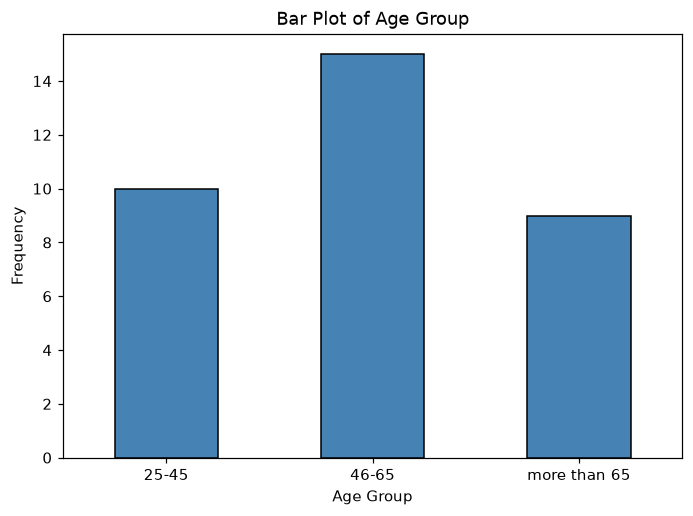

In [6]:
# Pass normalize=True inside value_counts() if you want Proportions instead of Frequency
counts = lung["age_grp"].value_counts(sort=False)

plt.figure()
counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.xlabel("Age Group")
plt.ylabel("Frequency")
plt.title("Bar Plot of Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### 2.2B Pie Chart (1 Categorical Variable)

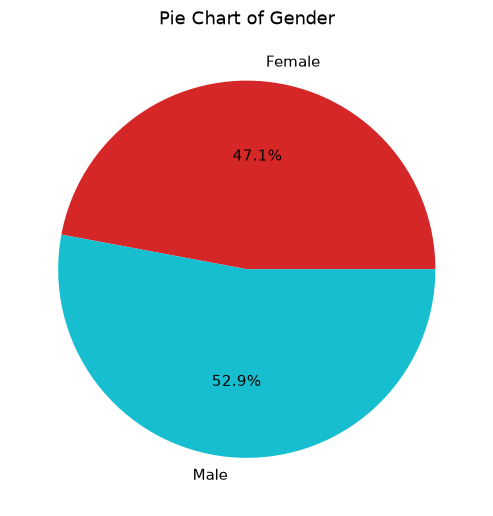

In [7]:
gender_counts = lung["gender"].value_counts(sort=False)

plt.figure()
plt.pie(gender_counts, labels=gender_counts.index, colors=["tab:red", "tab:cyan"], autopct="%1.1f%%")
plt.title("Pie Chart of Gender")
plt.tight_layout()
plt.show()

#### 2.2C Histogram (1 Quantitative Variable)

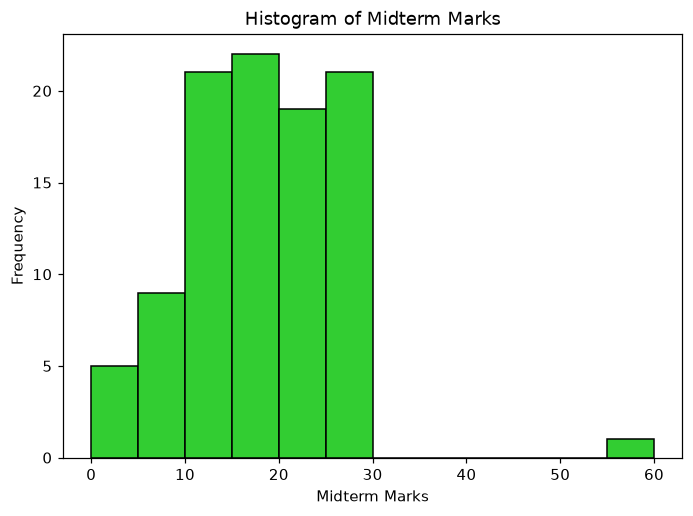

In [8]:
# Set density=True if you want Probability Density instead of Frequency
plt.figure()
plt.hist(mark, bins=np.arange(0, 65, 5), color="limegreen", edgecolor="black")
plt.xlabel("Midterm Marks")
plt.ylabel("Frequency")
plt.title("Histogram of Midterm Marks")
plt.tight_layout()
plt.show()

#### 2.2D Boxplot (1 Quantitative Variable)

Boxplot outliers: [60.]


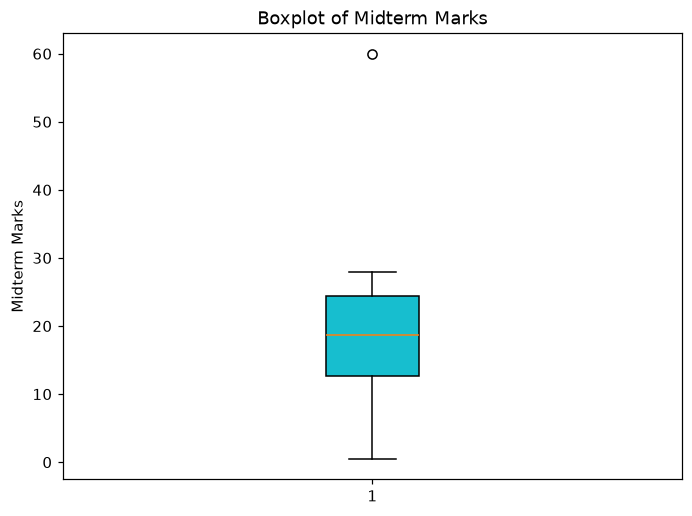

In [9]:
# Set orientation="horizontal" (and plt.xlabel) if you prefer a horizontal boxplot
plt.figure()
bp = plt.boxplot(mark.dropna(), orientation="vertical", patch_artist=True,
                 boxprops=dict(facecolor="tab:cyan"))
plt.ylabel("Midterm Marks")
plt.title("Boxplot of Midterm Marks")
plt.tight_layout()
plt.show()

# Optional: extract outlier values directly from the boxplot
print("Boxplot outliers:", bp["fliers"][0].get_data()[1])

---
### 2.3 Visualising Two Variables
- **Categorical vs Categorical:** Put the **explanatory variable on rows (`index`)** and **response variable on columns**, then condition on rows using `normalize="index"` (row percentages) before plotting a **Clustered** or **Stacked** bar plot.
- **Categorical vs Quantitative:** Side-by-side boxplots (`df.boxplot` or `plt.boxplot`).
- **Quantitative vs Quantitative:** Scatterplot (`plt.scatter(x, y)`) + Pearson correlation $r$ (`x.corr(y)`). Remember: $r$ only measures **linear** association, is sensitive to outliers, and **correlation $\neq$ causation**!

#### 1. Categorical vs Categorical $\to$ Contingency Table + Clustered / Stacked Bar Plot

In [10]:
bc = pd.read_csv("../data/breast_cancer.csv")
bc["pmh_use"] = bc["pmh"].map({2: "No", 3: "Yes"})
bc["cancer"]  = bc["bbd"].map({0: "Absent", 1: "Present"})
pmh_use = bc["pmh_use"].rename("PMH Usage")
cancer  = bc["cancer"].rename("Cancer")

# Step 1: Row-percentage contingency table (Explanatory = rows, Response = columns)
row_pct = pd.crosstab(bc["pmh_use"], bc["cancer"], normalize="index") * 100
print("Row-Percentage Contingency Table (rows sum to 100%):")
print(row_pct.round(2))

Row-Percentage Contingency Table (rows sum to 100%):
cancer   Absent  Present
pmh_use                 
No         68.2     31.8
Yes        60.5     39.5


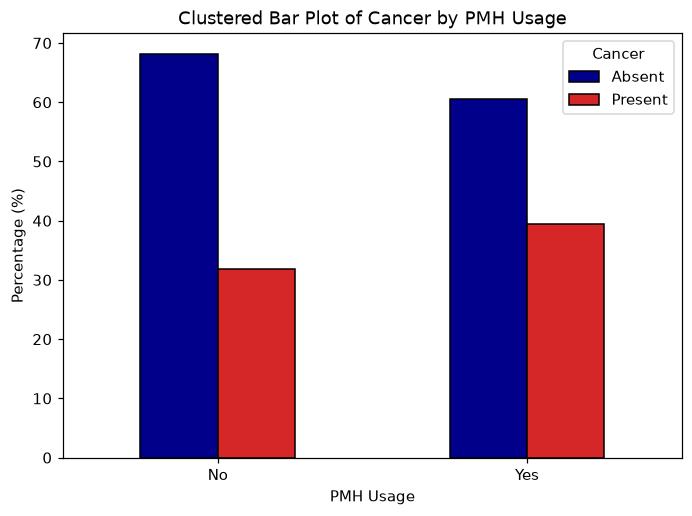

In [11]:
# 1A. Clustered Bar Plot (stacked=False by default)
row_pct.plot(kind="bar", color=["darkblue", "tab:red"], edgecolor="black")
plt.xlabel("PMH Usage")
plt.ylabel("Percentage (%)")
plt.title("Clustered Bar Plot of Cancer by PMH Usage")
plt.xticks(rotation=0)
plt.legend(title="Cancer")
plt.tight_layout()
plt.show()

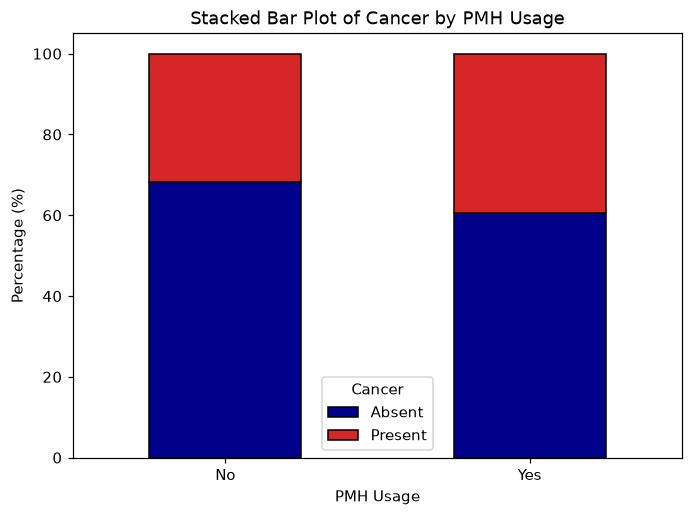

In [12]:
# 1B. Stacked Bar Plot (same code, just add stacked=True)
row_pct.plot(kind="bar", stacked=True, color=["darkblue", "tab:red"], edgecolor="black")
plt.xlabel("PMH Usage")
plt.ylabel("Percentage (%)")
plt.title("Stacked Bar Plot of Cancer by PMH Usage")
plt.xticks(rotation=0)
plt.legend(title="Cancer")
plt.tight_layout()
plt.show()

#### 2. Categorical vs Quantitative $\to$ Side-by-Side Boxplot

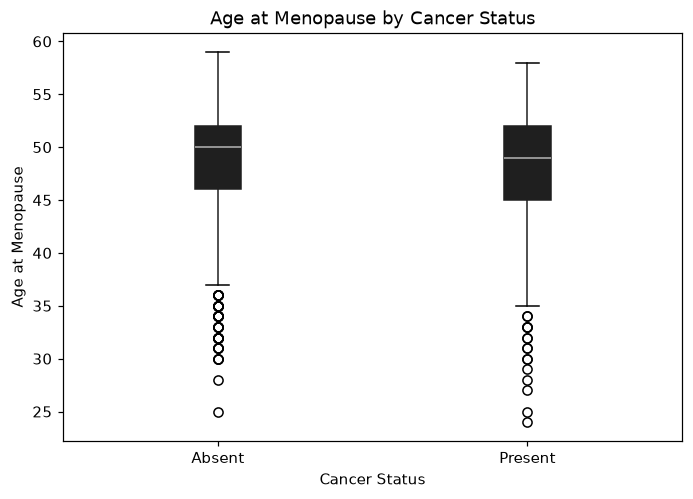

In [13]:
# Option A: Quickest pandas way (df.boxplot)
bc.boxplot(column="agemenop", by="cancer", grid=False, patch_artist=True)
plt.suptitle("")   # clears the automatic "Boxplot grouped by..." subtitle
plt.xlabel("Cancer Status")
plt.ylabel("Age at Menopause")
plt.title("Age at Menopause by Cancer Status")
plt.tight_layout()
plt.show()

Absent outliers: [32 25 32 35 32 36 36 35 32 36 30 33 31 34 33 31 35 34 34 35 36 30 34 33
 34 36 35 36 32 31 34 34 33 35 32 28 35 33 30 31 32]
Present outliers: [32 24 30 31 31 34 33 33 29 28 32 30 25 34 33 27]


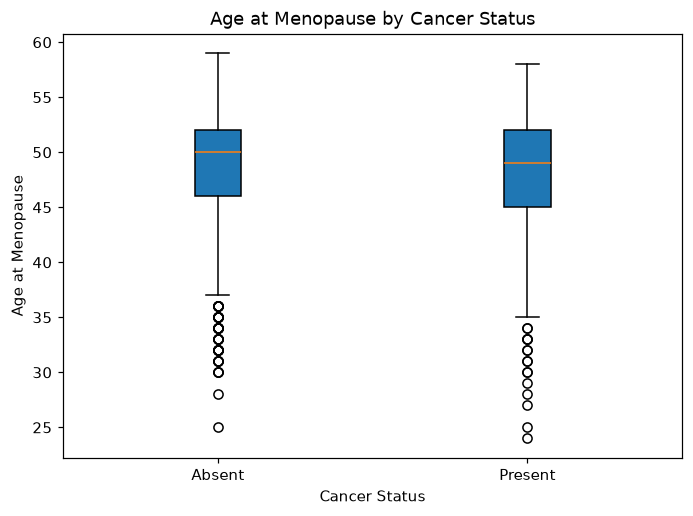

In [14]:
# Option B: Explicit plt.boxplot way (also lets you extract outliers per group)
absent_age  = bc[bc["cancer"] == "Absent"]["agemenop"].dropna()
present_age = bc[bc["cancer"] == "Present"]["agemenop"].dropna()

plt.figure()
bp = plt.boxplot([absent_age, present_age], tick_labels=["Absent", "Present"], patch_artist=True)
plt.xlabel("Cancer Status")
plt.ylabel("Age at Menopause")
plt.title("Age at Menopause by Cancer Status")
plt.tight_layout()
plt.show()

# Optional: extract outliers from each box
print("Absent outliers:", bp["fliers"][0].get_data()[1])
print("Present outliers:", bp["fliers"][1].get_data()[1])

#### 3. Quantitative vs Quantitative $\to$ Scatterplot + Correlation

Correlation r: 0.6265


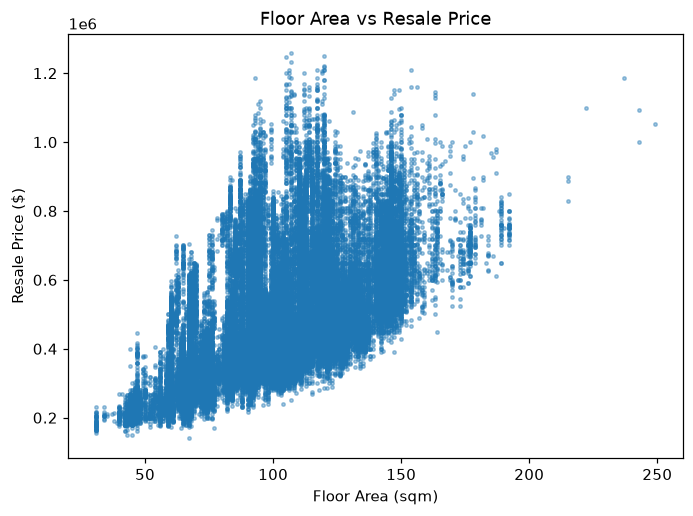

In [15]:
hdb = pd.read_csv("../data/hdb_2017_now.csv")

plt.figure()
plt.scatter(hdb["floor_area_sqm"], hdb["resale_price"], color="tab:blue", alpha=0.4, s=5)
plt.xlabel("Floor Area (sqm)")
plt.ylabel("Resale Price ($)")
plt.title("Floor Area vs Resale Price")
plt.tight_layout()
plt.show()

corr = hdb["floor_area_sqm"].corr(hdb["resale_price"])
print("Correlation r:", round(corr, 4))

---
<a id="topics-3-4"></a>
# Topics 3 & 4: Study Design, Confounding & Probability Foundations

*(Topics 3 and 4 are primarily conceptual/mathematical in ST1131, but Python is handy for Relative Risk, stratifying by confounders, combinatorics, and Bayes' Theorem calculations.)*

## Summary of Python Tools & Formulas (Topics 3 & 4)

| Function / Pattern | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `math.comb(n, k)` | `n`: total items (non-negative `int`)<br>`k`: number of items chosen without order (`int`) | Binomial coefficient $C^n_k = \binom{n}{k} = \frac{n!}{k!(n-k)!}$ |
| `math.factorial(n)` | `n`: non-negative `int` | Computes $n! = n \times (n-1) \times \dots \times 1$ |
| `pd.crosstab(exposure, outcome, normalize="index")` | `exposure`: explanatory group `Series`<br>`outcome`: binary outcome `Series` | Gives conditional risk $\hat{p} = P(\text{Event} \mid \text{Group})$ in each row for **Relative Risk** ($RR = \hat{p}_1 / \hat{p}_2$) and **Risk Difference** ($\hat{p}_1 - \hat{p}_2$) |
| `for lvl, sub in df.groupby(confounder): ...` | `confounder`: third recorded categorical variable $Z$ | **Stratification (slicing):** builds separate contingency tables / Relative Risks within each level of $Z$ to check for confounding or Simpson's Paradox |

### Quick Revision Cheat-Sheet
- **Topic 3 (Data Collection & Study Design):**
  - **Observational Study** (no intervention $\implies$ association only, vulnerable to confounders/lurking variables) vs **Experimental Study** (researcher **randomly assigns** treatments to experimental units $\implies$ can establish causation).
  - **Confounding Variable** (measured/recorded variable associated with *both* explanatory & response) vs **Lurking Variable** (unmeasured variable affecting both). **Simpson's Paradox:** direction of association reverses when data are aggregated vs stratified by a confounder.
  - **Biases:** **Sampling bias / Undercoverage** (unrepresentative sampling frame, convenience/volunteer sampling), **Non-response bias** (high refusal/non-reply rate), **Response bias** (leading questions, dishonest self-reporting, faulty instruments).
  - **Good Experimental Design:** Control / Placebo group (accounts for placebo/expectation effect), Random Assignment (balances confounders), Double-Blinding (neither subjects nor evaluators know group), Replication (adequate sample size $n$), Blocking (group similar subjects first, then randomize within blocks).
- **Topic 4 (Probability & Diagnostic Testing):**
  - **Addition Rule:** $P(A \cup B) = P(A) + P(B) - P(A \cap B)$.
  - **Mutually Exclusive (Disjoint):** $A \cap B = \emptyset \implies P(A \cap B) = 0$. *(Trap: If $P(A)>0$ and $P(B)>0$, mutually exclusive events are **NEVER** independent because $P(A \cap B) = 0 \neq P(A)P(B)$!)*
  - **Independence:** $P(A \cap B) = P(A)P(B) \iff P(A \mid B) = P(A)$.
  - **Diagnostic Screening ($D$ = disease, $+$ = positive test):**
    - **Prevalence** $= P(D)$, **Sensitivity** $= P(+ \mid D)$, **Specificity** $= P(- \mid D^c)$.
    - False Positive Rate $= P(+ \mid D^c) = 1 - \text{Specificity}$; False Negative Rate $= P(- \mid D) = 1 - \text{Sensitivity}$.
    - **Law of Total Probability:** $P(+) = P(+ \mid D)P(D) + P(+ \mid D^c)P(D^c)$.
    - **Bayes' Theorem (PPV):** $P(D \mid +) = \dfrac{P(+ \mid D)P(D)}{P(+)}$. *(Lower prevalence $P(D) \implies$ lower $P(D \mid +)$ even if sensitivity & specificity stay high!)*

In [16]:
# 1. Relative Risk & Difference in Proportions (Breast Cancer PMH example)
prop_table = pd.crosstab(pmh_use, cancer, normalize="index")
risk_yes = prop_table.loc["Yes", "Present"]
risk_no  = prop_table.loc["No", "Present"]
print(f"Risk (PMH=Yes): {risk_yes:.4f} | Risk (PMH=No): {risk_no:.4f}")
print(f"Relative Risk (RR) = {risk_yes / risk_no:.4f} | Risk Difference = {risk_yes - risk_no:.4f}")

# 2. Reusable Bayes' Theorem Calculator for Diagnostic Tests
prev = 0.01   # P(D)
sens = 0.96   # P(+ | D)
spec = 0.95   # P(- | D^c)

p_pos = sens * prev + (1 - spec) * (1 - prev)   # Law of Total Probability: P(+)
ppv   = (sens * prev) / p_pos                   # Bayes' Theorem: P(D | +)
print(f"\nP(+) = {p_pos:.5f} | Positive Predictive Value P(D | +) = {ppv:.4f}")

Risk (PMH=Yes): 0.3950 | Risk (PMH=No): 0.3180
Relative Risk (RR) = 1.2421 | Risk Difference = 0.0770

P(+) = 0.05910 | Positive Predictive Value P(D | +) = 0.1624


---
<a id="topic-5"></a>
# Topic 5: Random Variables & Probability Distributions (`scipy.stats`)

## Summary of Functions & Arguments (Topic 5)

Every distribution in `scipy.stats` (`bernoulli`, `binom`, `norm`, `t`, etc.) shares the **exact same method names** — only the distribution parameters (`...`) change:

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `<dist>.pmf(k, ...)` | `k`: integer value $x$ (or array `np.arange(...)`)<br>`...`: distribution parameters (see table below) | $P(X = x)$, for **discrete** distributions only (`bernoulli`, `binom`) |
| `<dist>.pdf(x, ...)` | `x`: value $x$ (or `np.linspace(...)` grid)<br>`...`: distribution parameters | Height of the density curve $f(x)$, for **continuous** distributions only. **Does NOT return a probability!** |
| `<dist>.cdf(x, ...)` | `x`: cutoff value $x$<br>`...`: distribution parameters | $P(X \le x)$, cumulative probability / area to the **left** (includes $x$ for discrete!) |
| `<dist>.sf(x, ...)` | `x`: cutoff value $x$<br>`...`: distribution parameters | $P(X > x) = 1 - P(X \le x)$, survival probability / area strictly to the **right** |
| `<dist>.ppf(q, ...)` | `q`: cumulative **left-tail** probability in `(0, 1)` *(if given top-$p$ right-tail area, input `1 - p`!)*<br>`...`: distribution parameters | Quantile $x_q$ such that $P(X \le x_q) = q$ (inverse of `.cdf`) |
| `<dist>.mean(...)`, `.var(...)`, `.std(...)` | `...`: distribution parameters only | Theoretical mean $\mu = E(X)$, variance $\sigma^2 = \text{Var}(X)$, and SD $\sigma$ |
| `<dist>.rvs(..., size=1)` | `...`: distribution parameters<br>`size`: integer count `N` or tuple `(N, n)` | Draws random simulated values from the distribution |
| `np.random.seed(seed)` | `seed`: non-negative integer (e.g. `1131`) | Fixes random seed so `.rvs(...)` / `np.random` simulations are reproducible |

### Exact Parameter Arguments (`...`) for Each Distribution in Topic 5

| Distribution | How to Call (`...` Arguments) | Caution / Formula Notes |
|---|---|---|
| $X \sim \text{Bernoulli}(p)$ | `bernoulli.<method>(x, p)`<br>• `x`: `0` or `1`<br>• `p`: probability of success ($1$) | Same as `binom.<method>(x, 1, p)`. $E(X)=p$, $\text{Var}(X)=p(1-p)$ |
| $X \sim \text{Bin}(n, p)$ | `binom.<method>(x, n, p)`<br>• `x`: integer count in `0, 1, ..., n`<br>• `n`: total independent trials<br>• `p`: probability of success per trial | $E(X)=np$, $\text{Var}(X)=np(1-p)$.<br>**Discrete trap:** $P(X \ge k) = P(X > k-1) =$ **`binom.sf(k - 1, n, p)`**! |
| $X \sim N(\mu, \sigma^2)$ | `norm.<method>(x, loc=0, scale=1)`<br>• `x` (or `q` for `.ppf`): value / probability<br>• `loc`: mean $\mu$ (default `0`)<br>• `scale`: **SD $\sigma = \sqrt{\sigma^2}$** (default `1`) | **CRITICAL:** Lectures write $N(\mu, \sigma^2)$, e.g. $N(80, 144)$, so you **must** pass `scale=np.sqrt(144)` (`12`), **NOT** `144`! Omit `loc, scale` for standard normal $Z \sim N(0,1)$ |
| Custom Discrete Table $(x_i, p_i)$ | `mu = np.sum(x * probs)`<br>`var = np.sum((x - mu)**2 * probs)` | Pass 1D NumPy arrays `x` and `probs` (check `np.isclose(probs.sum(), 1)`). Linear rules: $E(aX+b)=aE(X)+b$, $\text{Var}(aX+b)=a^2\text{Var}(X)$; independent sum/diff: $\text{Var}(X \pm Y) = \text{Var}(X) + \text{Var}(Y)$ |

---

### 5.1 Custom Discrete RVs & Binomial Distribution

In [17]:
np.random.seed(1131)

# 1. Custom Discrete RV: E(X), Var(X), and Linear Transformation Y = 1.5X - 0.5
x_vals  = np.array([0, 1, 2, 3, 4])
x_probs = np.array([0.15, 0.35, 0.25, 0.15, 0.10])
mu_x  = np.sum(x_vals * x_probs)
var_x = np.sum((x_vals - mu_x)**2 * x_probs)
print(f"Custom Discrete X -> E(X) = {mu_x:.4f}, Var(X) = {var_x:.4f}, SD(X) = {np.sqrt(var_x):.4f}")
print(f"Transformed Y = 1.5X - 0.5 -> E(Y) = {1.5*mu_x - 0.5:.4f}, Var(Y) = {1.5**2 * var_x:.4f}")

# 2. Binomial Distribution: X ~ Bin(10, 0.25)
n, p = 10, 0.25
print(f"\nBin(10, 0.25): P(X = 5) = {binom.pmf(5, n, p):.4f} (by math.comb: {math.comb(n, 5) * p**5 * (1-p)**5:.4f})")
print(f"At most 4  P(X <= 4) = {binom.cdf(4, n, p):.4f}")
print(f"At least 5 P(X >= 5) = P(X > 4) = {binom.sf(4, n, p):.4f} (== {1 - binom.cdf(4, n, p):.4f})")
print(f"Mean = {binom.mean(n, p)}, Variance = {binom.var(n, p)}")

Custom Discrete X -> E(X) = 1.7000, Var(X) = 1.4100, SD(X) = 1.1874
Transformed Y = 1.5X - 0.5 -> E(Y) = 2.0500, Var(Y) = 3.1725

Bin(10, 0.25): P(X = 5) = 0.0584 (by math.comb: 0.0584)
At most 4  P(X <= 4) = 0.9219
At least 5 P(X >= 5) = P(X > 4) = 0.0781 (== 0.0781)
Mean = 2.5, Variance = 1.875


### 5.2 Normal Distribution, Quantiles, Standardisation & Continuity Correction

When $n$ is large and $np(1-p) \ge 5$, $X \sim \text{Bin}(n, p)$ is well approximated by $Y \sim N\big(np,\; np(1-p)\big)$ with **continuity correction** ($\pm 0.5$):

| Discrete Binomial Event | Whole Numbers Included | Normal Approximation $Y \sim N(np, np(1-p))$ | Python Code (`sigma = np.sqrt(n*p*(1-p))`) |
|---|---|---|---|
| $P(X \le k)$ | $\dots, k-1, k$ | $P(Y \le k + 0.5)$ | `norm.cdf(k + 0.5, n*p, sigma)` |
| $P(X < k)$ | $\dots, k-2, k-1$ | $P(Y \le k - 0.5)$ | `norm.cdf(k - 0.5, n*p, sigma)` |
| $P(X \ge k)$ | $k, k+1, \dots$ | $P(Y \ge k - 0.5)$ | `norm.sf(k - 0.5, n*p, sigma)` |
| $P(X > k)$ | $k+1, k+2, \dots$ | $P(Y \ge k + 0.5)$ | `norm.sf(k + 0.5, n*p, sigma)` |
| $P(X = k)$ | $k$ only | $P(k - 0.5 \le Y \le k + 0.5)$ | `norm.cdf(k + 0.5, n*p, sigma) - norm.cdf(k - 0.5, n*p, sigma)` |

P(60 <= X <= 73) = 0.2320
P(X >= 90)       = 0.2023
90th percentile (top 10% cutoff): x = 95.3786
Direct norm.cdf(73, 80, 12) = 0.2798 == Standardised norm.cdf(z) = 0.2798

Bin(25, 0.4) P(X <= 8): Exact = 0.2735 | Normal w/ CC = 0.2701
Bin(25, 0.4) P(X = 10): Exact = 0.1612 | Normal w/ CC = 0.1617


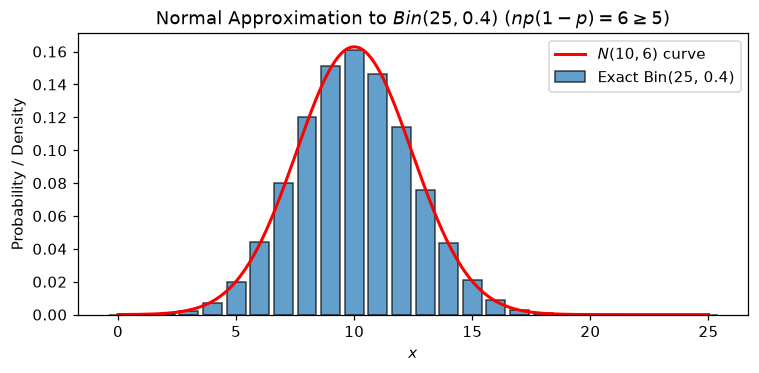

In [18]:
# 1. Normal probabilities & quantiles for X ~ N(80, 144) -> mu = 80, sigma = sqrt(144) = 12
mu, sigma = 80, np.sqrt(144)
print(f"P(60 <= X <= 73) = {norm.cdf(73, mu, sigma) - norm.cdf(60, mu, sigma):.4f}")
print(f"P(X >= 90)       = {norm.sf(90, mu, sigma):.4f}")
print(f"90th percentile (top 10% cutoff): x = {norm.ppf(0.90, mu, sigma):.4f}")

# Standardisation check: Z = (X - mu) / sigma ~ N(0, 1)
z_73 = (73 - mu) / sigma
print(f"Direct norm.cdf(73, 80, 12) = {norm.cdf(73, mu, sigma):.4f} == Standardised norm.cdf(z) = {norm.cdf(z_73):.4f}")

# 2. Normal Approximation to Binomial with Continuity Correction: Bin(25, 0.4), np(1-p) = 6 >= 5
n_b, p_b = 25, 0.4
mu_b, sd_b = n_b * p_b, np.sqrt(n_b * p_b * (1 - p_b))
print(f"\nBin(25, 0.4) P(X <= 8): Exact = {binom.cdf(8, n_b, p_b):.4f} | Normal w/ CC = {norm.cdf(8.5, mu_b, sd_b):.4f}")
print(f"Bin(25, 0.4) P(X = 10): Exact = {binom.pmf(10, n_b, p_b):.4f} | Normal w/ CC = {norm.cdf(10.5, mu_b, sd_b) - norm.cdf(9.5, mu_b, sd_b):.4f}")

# Visualise Binomial bars + Normal Approximation curve
k = np.arange(0, n_b + 1)
xs = np.linspace(0, n_b, 400)
plt.figure(figsize=(7, 3.5))
plt.bar(k, binom.pmf(k, n_b, p_b), color="tab:blue", alpha=0.7, edgecolor="black", label="Exact Bin(25, 0.4)")
plt.plot(xs, norm.pdf(xs, mu_b, sd_b), color="red", linewidth=2, label=r"$N(10, 6)$ curve")
plt.xlabel(r"$x$")
plt.ylabel("Probability / Density")
plt.title(r"Normal Approximation to $Bin(25, 0.4)$ ($np(1-p) = 6 \geq 5$)")
plt.legend()
plt.tight_layout()
plt.show()

---
<a id="topic-6"></a>
# Topic 6: Sampling Distributions & Central Limit Theorem (CLT)

## Summary of Functions & Arguments (Topic 6)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `np.random.seed(seed)` | `seed`: integer (e.g. `1131`) | Resets random number generator so simulation output is identical every run |
| `np.random.normal(loc=0.0, scale=1.0, size=None)` | `loc`: population mean $\mu$<br>`scale`: **population SD $\sigma$** (not $\sigma^2$!)<br>`size`: `n` (1D sample) or **`(N, n)`** ($N$ rows, each a sample of size $n$) | Simulates random draws from $N(\mu, \sigma^2)$ |
| `np.random.exponential(scale=1.0, size=None)` | `scale`: population **mean** $\lambda$ (also equals SD $\lambda$)<br>`size`: `n` or **`(N, n)`** | Simulates draws from a right-skewed Exponential distribution with mean `scale` *(avoid naming variable `lambda`!)* |
| `np.random.binomial(n, p, size=None)` | `n`: sample size / trials per poll<br>`p`: true population proportion<br>`size`: `N` (number of simulated polls) | Draws $N$ counts from $\text{Bin}(n, p)$. Divide by `n` (`np.random.binomial(n, p, size=N) / n`) to simulate $N$ sample proportions $\hat{p}$! |
| `np.random.choice(a, size=None, replace=True, p=None)` | `a`: 1D population array/list to sample from<br>`size`: `n` or **`(N, n)`**<br>`replace`: `True` (with replacement, default), `False` (without)<br>`p`: optional probability weights | Draws random sample(s) from an existing array/population |
| `np.random.randint(low, high, size=None)` | `low`: inclusive min integer<br>`high`: **exclusive** max integer (use `1, 7` for fair 6-sided die!)<br>`size`: `n` or **`(N, n)`** | Draws discrete uniform random integers from `{low, ..., high - 1}` |
| `N_samples.mean(axis=1)` | `axis=1`: averages **across each row** of a `(N, n)` 2D array | Produces a 1D array of $N$ simulated sample means $\bar{x}_1, \dots, \bar{x}_N$ |
| `np.mean(bool_condition)` | `bool_condition`: boolean array, e.g. `np.abs(p_hat - p) <= 3*se` | Because `True == 1` and `False == 0`, returns the **empirical proportion** of simulated samples satisfying the condition |

### Key Concepts & Formulas (Topic 6)
1. **Three Distributions — Don't Mix Them Up:**
   - **Population distribution:** distribution of $X$ across the entire population (mean $\mu$, SD $\sigma$, fixed/unknown).
   - **Sample (data) distribution:** histogram of $n$ observations in **one** collected sample (resembles the population shape).
   - **Sampling distribution:** probability distribution of a **statistic** ($\bar{X}$ or $\hat{p}$) across all possible random samples of size $n$.
2. **Sampling Distribution of the Sample Mean $\bar{X}$:**
   - For **any** population and **any** $n$: $E(\bar{X}) = \mu$ and $SD(\bar{X}) = \dfrac{\sigma}{\sqrt{n}}$.
   - If the population is **Normal** $N(\mu, \sigma^2)$: $\bar{X} \sim N\left(\mu, \dfrac{\sigma^2}{n}\right)$ **exact for any $n$**.
   - **Central Limit Theorem (CLT):** Even if the population is non-normal/skewed, for large sample size **$n \ge 30$** (rule of thumb), $\bar{X} \approx N\left(\mu, \dfrac{\sigma^2}{n}\right)$ approximately.
3. **Sample Size $n$ vs Number of Simulated Samples $N$:**
   - Increasing **$n$** changes the **true** sampling distribution (shrinks spread $\sigma/\sqrt{n}$ and makes skewed distributions bell-shaped via CLT).
   - Increasing **$N$** (simulation-only!) does **not** change the true curve — it only makes the simulated histogram smoother.
4. **Sampling Distribution of Sample Proportion $\hat{p} = X/n$:**
   - $E(\hat{p}) = p$, $SD(\hat{p}) = \sqrt{\dfrac{p(1-p)}{n}}$. When $np(1-p) \ge 5$ (or $np \ge 5$ and $n(1-p) \ge 5$), $\hat{p} \approx N\left(p, \dfrac{p(1-p)}{n}\right)$.

Simulated p_hat -> Mean: 0.5310 (true p=0.531), SD: 0.0079 (theory=0.0080)
Proportion within 3 SE of p: 0.9976


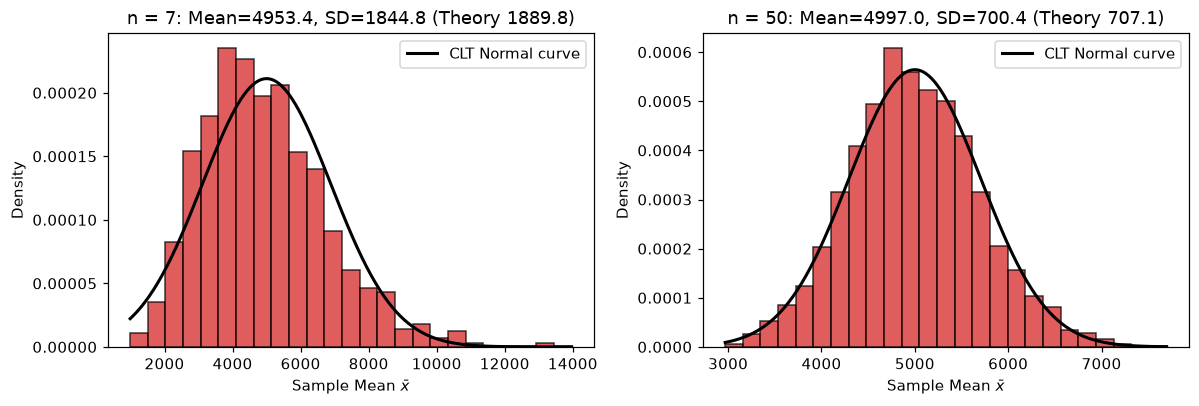

In [19]:
np.random.seed(151)

# 1. CLT Demo on a heavily right-skewed Exponential(mean=5000) population: n = 7 vs n = 50
lam = 5000
N = 2000

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(axes, [7, 50]):
    means = np.random.exponential(scale=lam, size=(N, n)).mean(axis=1)
    xs = np.linspace(means.min(), means.max(), 300)
    ax.hist(means, bins=25, density=True, color="tab:red", alpha=0.75, edgecolor="black")
    ax.plot(xs, norm.pdf(xs, loc=lam, scale=lam / np.sqrt(n)), color="black", lw=2, label="CLT Normal curve")
    ax.set_title(f"n = {n}: Mean={means.mean():.1f}, SD={means.std(ddof=1):.1f} (Theory {lam/np.sqrt(n):.1f})")
    ax.set_xlabel(r"Sample Mean $\bar{x}$")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

# 2. Sampling Distribution of Sample Proportion p_hat (n = 3889, p = 0.531)
np.random.seed(3889)
n_poll, p_true = 3889, 0.531
p_hats = np.random.binomial(n_poll, p_true, size=10000) / n_poll
se_true = np.sqrt(p_true * (1 - p_true) / n_poll)
print(f"Simulated p_hat -> Mean: {p_hats.mean():.4f} (true p={p_true}), SD: {p_hats.std(ddof=1):.4f} (theory={se_true:.4f})")
print(f"Proportion within 3 SE of p: {np.mean(np.abs(p_hats - p_true) <= 3 * se_true):.4f}")

---
<a id="topic-7"></a>
# Topic 7: Confidence Intervals

$$\text{Confidence Interval} = \text{Point Estimate} \pm \text{Multiplier} \times \text{Standard Error (SE)}$$

## Summary of Functions & Arguments (Topic 7)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `norm.ppf(q)` | `q`: **`1 - alpha / 2`** (e.g. `0.975` for 95% CI, `0.95` for 90% CI, `0.995` for 99% CI)<br>`loc=0, scale=1` omitted | Standard normal multiplier $z_{1-\alpha/2}$ (used for **proportion $p$ CIs** and **all sample-size formulas**) |
| `t.ppf(q, df)` | `q`: **`1 - alpha / 2`** (two-tailed quantile)<br>`df`: degrees of freedom **`n - 1`** | $t$-distribution multiplier $t_{n-1,\, 1-\alpha/2}$ (used for **population mean $\mu$ CI** when $\sigma$ is unknown) |
| `np.sqrt(p_hat * (1 - p_hat) / n)` | `p_hat`: sample proportion $\hat{p}$<br>`n`: sample size | Standard error $SE(\hat{p})$ for a proportion CI *(uses $\hat{p}$ because true $p$ is unknown; check $n\hat{p}(1-\hat{p}) \ge 5$)* |
| `s / np.sqrt(n)` | `s`: **sample** SD (`np.std(data, ddof=1)` or `series.std()`)<br>`n`: `len(data)` | Standard error $SE(\bar{x})$ for a population mean CI |
| `norm.interval(confidence, loc, scale)` | `confidence`: CI level in `(0, 1)`, e.g. **`0.95`**<br>`loc`: point estimate `p_hat`<br>`scale`: standard error `se` | Shortcut returning `(lower, upper)` $100(1-\alpha)\%$ CI for population proportion $p$ |
| `t.interval(confidence, df, loc, scale)` | `confidence`: CI level in `(0, 1)`, e.g. **`0.95`**<br>`df`: **`n - 1`**<br>`loc`: sample mean `x_bar`<br>`scale`: standard error `s / np.sqrt(n)` | Shortcut returning `(lower, upper)` $100(1-\alpha)\%$ CI for population mean $\mu$ |
| `math.ceil(x)` *(or `np.ceil(x)`)* | `x`: unrounded minimum sample size `n_needed` | **Always round UP** to the next integer when finding required sample size $n$ (`round()` can make $n$ too small!) |

### Formula & Assumptions Reference (Topic 7)

| Parameter | $100(1-\alpha)\%$ Confidence Interval Formula | Assumptions / Validity Check | Sample Size $n$ for Width $\le D$ *(note: Margin of Error $M = D/2$)* |
|---|---|---|---|
| **Proportion $p$** | $\hat{p} \pm z_{1-\alpha/2}\sqrt{\dfrac{\hat{p}(1-\hat{p})}{n}}$ | Random sample & $n\hat{p}(1-\hat{p}) \ge 5$ | $n \ge \left(\dfrac{2 z_{1-\alpha/2}}{D}\right)^2 p(1-p)$<br>*(Use conservative **$p = 0.5$** if $p$ is unknown)* |
| **Mean $\mu$** ($\sigma$ unknown) | $\bar{x} \pm t_{n-1,\, 1-\alpha/2}\dfrac{s}{\sqrt{n}}$ | Random sample & data roughly normal/symmetric (or large $n \ge 30$) | $n \ge \left(\dfrac{2 z_{1-\alpha/2}\, s}{D}\right)^2$<br>*(Uses $z_{1-\alpha/2}$ since $n$, hence $df$, is unknown; $s$ from pilot study)* |

> **Interpreting 95% Confidence:** "We are 95% confident that the true parameter lies in `(lower, upper)`." Over many repeated random samples, ~95% of intervals constructed this way will cover the fixed true parameter. **Never** say "there is a 95% probability that $\mu$ moves/falls inside `(3.06, 3.36)`" — once computed, both $\mu$ and the numbers `(3.06, 3.36)` are fixed!

In [20]:
# 1. 95% CI for a Population Proportion p (Election: n = 3889, p_hat = 0.531)
n_p, p_hat = 3889, 0.531
conf = 0.95
alpha = 1 - conf
print(f"Assumption check n*p_hat*(1-p_hat) = {n_p * p_hat * (1 - p_hat):.2f} >= 5")

se_p = np.sqrt(p_hat * (1 - p_hat) / n_p)
z_mult = norm.ppf(1 - alpha / 2)
ci_p_manual = (p_hat - z_mult * se_p, p_hat + z_mult * se_p)
ci_p_short  = norm.interval(conf, loc=p_hat, scale=se_p)
print(f"95% CI for p (manual):   ({ci_p_manual[0]:.4f}, {ci_p_manual[1]:.4f})")
print(f"95% CI for p (shortcut): ({ci_p_short[0]:.4f}, {ci_p_short[1]:.4f})")

# 2. 95% CI for a Population Mean mu (Baby weights: n = 47, x_bar = 3.208, s = 0.506)
n_m, x_bar, s = 47, 3.208, 0.506
se_m = s / np.sqrt(n_m)
t_mult = t.ppf(1 - alpha / 2, df=n_m - 1)   # Note: variable named t_mult, NEVER 't'!
ci_m_manual = (x_bar - t_mult * se_m, x_bar + t_mult * se_m)
ci_m_short  = t.interval(conf, df=n_m - 1, loc=x_bar, scale=se_m)
print(f"\n95% CI for mu (manual):   ({ci_m_manual[0]:.3f}, {ci_m_manual[1]:.3f}) | t-multiplier = {t_mult:.4f}")
print(f"95% CI for mu (shortcut): ({ci_m_short[0]:.3f}, {ci_m_short[1]:.3f})")

# 3. Sample Size Determination (Target total width D; if given Margin of Error M, set D = 2 * M!)
D_prop = 0.10
n_prop_needed = (2 * norm.ppf(0.975) / D_prop)**2 * 0.5 * (1 - 0.5)
print(f"\nSample size for p (95% CI, width <= 0.10, p=0.5): {n_prop_needed:.2f} -> math.ceil = {math.ceil(n_prop_needed)}")

D_mean, s_pilot = 0.20, 0.5064
n_mean_needed = (2 * norm.ppf(0.975) * s_pilot / D_mean)**2
print(f"Sample size for mu (95% CI, width <= 0.20):       {n_mean_needed:.2f} -> math.ceil = {math.ceil(n_mean_needed)}")

Assumption check n*p_hat*(1-p_hat) = 968.51 >= 5
95% CI for p (manual):   (0.5153, 0.5467)
95% CI for p (shortcut): (0.5153, 0.5467)

95% CI for mu (manual):   (3.059, 3.357) | t-multiplier = 2.0129
95% CI for mu (shortcut): (3.059, 3.357)

Sample size for p (95% CI, width <= 0.10, p=0.5): 384.15 -> math.ceil = 385
Sample size for mu (95% CI, width <= 0.20):       98.51 -> math.ceil = 99


---
<a id="topic-8"></a>
# Topic 8: Hypothesis Testing

Every hypothesis test follows **5 Steps**: (1) Check assumptions $\to$ (2) State $H_0$ and $H_1$ $\to$ (3) Compute test statistic $\to$ (4) Find $p$-value $\to$ (5) Conclusion in context (reject $H_0$ if $p\text{-value} \le \alpha$).

## Summary of Functions & Arguments (Topic 8)

| Function | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `norm.sf(z)`<br>`norm.cdf(z)`<br>`2 * norm.sf(abs(z))` | `z`: observed $Z$-statistic $\dfrac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}}$ *(uses **$p_0$**, NOT $\hat{p}$!)* | Exact $p$-value for **proportion $Z$-test**:<br>• `norm.sf(z)`: right-sided ($H_1: p > p_0$)<br>• `norm.cdf(z)`: left-sided ($H_1: p < p_0$)<br>• `2 * norm.sf(abs(z))`: two-sided ($H_1: p \neq p_0$) |
| `t.sf(T, df)`<br>`t.cdf(T, df)`<br>`2 * t.sf(abs(T), df)` | `T`: observed $T$-statistic<br>`df`: degrees of freedom (`n - 1` for 1-sample/paired, `n1 + n2 - 2` for pooled 2-sample) | Exact $p$-value from $t_{df}$ for right-sided (`sf`), left-sided (`cdf`), or two-sided (`2 * sf(abs(T))`) $t$-tests when working from summary statistics |
| `ttest_1samp(a, popmean, alternative="two-sided", axis=0)` | `a`: 1D sample array/`Series` (drop `NaN`s if any)<br>`popmean`: null value $\mu_0$ under $H_0: \mu = \mu_0$<br>`alternative`: `"two-sided"` ($\mu \neq \mu_0$), `"greater"` ($\mu > \mu_0$), or `"less"` ($\mu < \mu_0$)<br>`axis`: `1` to test all rows of a `(N, n)` simulated matrix at once | One-sample $t$-test on raw data. Returns result object with `.statistic`, `.pvalue`, and `.df` |
| `levene(sample1, sample2)` | `sample1`, `sample2`: two independent numeric samples | **Levene's Test for Equal Variances** ($H_0: \sigma_1^2 = \sigma_2^2$ vs $H_1: \sigma_1^2 \neq \sigma_2^2$).<br>• Large $p > \alpha$ $\implies$ do not reject $H_0$ $\implies$ set **`equal_var=True`**<br>• Small $p \le \alpha$ $\implies$ reject $H_0$ $\implies$ set **`equal_var=False`** |
| `ttest_ind(a, b, equal_var=True, alternative="two-sided")` | `a`: Sample 1 (`Series`/array)<br>`b`: Sample 2 (`Series`/array) — **tests $\mu_a - \mu_b$**, so order matters!<br>`equal_var`: `True` (pooled $t$-test, $df=n_1+n_2-2$) or `False` (Welch's $t$-test)<br>`alternative`: `"two-sided"` ($\mu_a - \mu_b \neq 0$), `"greater"` ($\mu_a - \mu_b > 0$), `"less"` ($\mu_a - \mu_b < 0$) | Two-sample **independent** $t$-test comparing $\mu_a$ and $\mu_b$. Access `.statistic`, `.pvalue`, `.df` |
| `ttest_rel(a, b, alternative="two-sided")` | `a`, `b`: **paired/matched** arrays of identical length (**tests mean of $D = a - b$**)<br>`alternative`: `"two-sided"` ($\mu_D \neq 0$), `"greater"` ($\mu_D > 0$), `"less"` ($\mu_D < 0$) | **Paired (dependent)** $t$-test. Equivalent to `ttest_1samp(a - b, popmean=0, alternative=...)` |
| `res.confidence_interval(confidence_level=0.95)` | `confidence_level`: e.g. **`0.95`** or **`0.99`**<br>*(Call on a **two-sided** `ttest_*` result `res`; a one-sided test returns an infinite bound!)* | Returns CI object with `.low` and `.high` for $\mu$, $\mu_a - \mu_b$, or $\mu_D$ |
| `probplot(x, dist="norm", plot=plt)` | `x`: 1D numeric sample or residuals<br>`plot`: pass `plt` (single figure) or `axes[i]` (subplot) | Normal **QQ Plot** with reference line (points hugging the line $\implies$ approximately normal) |
| `shapiro(x)` | `x`: 1D numeric sample | **Shapiro-Wilk Normality Test** ($H_0$: data is from a normal distribution). Large `.pvalue > alpha` $\implies$ normality is plausible *(sensitive to minor deviations when $n$ is huge)* |

### Key Conceptual Reminders (Topic 8)
- **CI vs Two-Sided Test Consistency:** For means ($\mu$), a two-sided $t$-test at level $\alpha$ rejects $H_0: \mu = \mu_0 \iff \mu_0$ lies **outside** the $100(1-\alpha)\%$ CI (identical $SE = s/\sqrt{n}$). For proportions ($p$), borderline cases can occasionally disagree because the test uses $SE_0 = \sqrt{p_0(1-p_0)/n}$ while the CI uses $\sqrt{\hat{p}(1-\hat{p})/n}$.
- **Errors & Power:** Type I error = rejecting true $H_0$ (prob $= \alpha$); Type II error = failing to reject false $H_0$ (prob $= \beta$); **Power** $= 1 - \beta$. Lowering $\alpha$ decreases Type I error but increases $\beta$ (lowers power); increasing sample size **$n$** increases power without raising $\alpha$.

1-Sample Proportion Z = 3.866, right-sided p-value = 5.522e-05

Gentoo 1-Sample t-test: T = 31.33, df = 122, p = 3.518e-60
95% CI = (46.95, 48.05) | Shapiro-Wilk W = 0.9727, p = 0.0135

Bike Levene p = 0.9992 -> equal_var=True
2-Sample Ind t-test: T = 7.0568, df = 729.0, p = 3.971e-12, 95% CI = (733.25, 1298.48)

Paired t-test (Yes - No): T = 5.4563, df = 31, one-sided p = 2.902e-06
99% Two-Sided CI for Mean Difference: (25.165, 76.085)


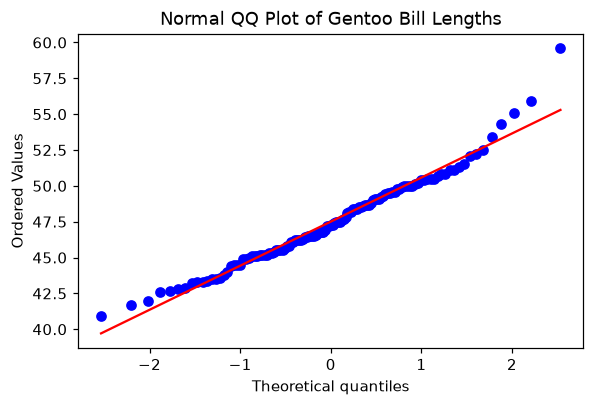

In [21]:
# 1. One-Sample Proportion Z-test (H0: p = 0.5 vs H1: p > 0.5)
n, p_hat, p0 = 3889, 0.531, 0.5
se0 = np.sqrt(p0 * (1 - p0) / n)   # Uses p0 under H0!
z_stat = (p_hat - p0) / se0
print(f"1-Sample Proportion Z = {z_stat:.3f}, right-sided p-value = {norm.sf(z_stat):.3e}")

# 2. One-Sample t-test + Normality Check (Gentoo Penguin Bill Length: H0: mu = 38.8 vs H1: mu != 38.8)
gentoo = pd.read_csv("../data/billlength_Gentoo.csv")["length"]
res_1s = ttest_1samp(gentoo, popmean=38.8, alternative="two-sided")
ci_1s  = res_1s.confidence_interval(0.95)
sw_res = shapiro(gentoo)
print(f"\nGentoo 1-Sample t-test: T = {res_1s.statistic:.2f}, df = {res_1s.df}, p = {res_1s.pvalue:.3e}")
print(f"95% CI = ({ci_1s.low:.2f}, {ci_1s.high:.2f}) | Shapiro-Wilk W = {sw_res.statistic:.4f}, p = {sw_res.pvalue:.4f}")

# 3. Two Independent Samples: Levene's Test -> Pooled vs Welch's t-test (Bike Rentals)
bike = pd.read_csv("../data/bike_day.csv")
good = bike.loc[bike["weathersit"] == 1, "cnt"]
bad  = bike.loc[bike["weathersit"] != 1, "cnt"]

lev_p = levene(good, bad).pvalue
eq_var = lev_p > 0.05   # True here (p = 0.9992 > 0.05) -> Pooled t-test
res_ind = ttest_ind(good, bad, equal_var=eq_var, alternative="two-sided")
ci_ind  = res_ind.confidence_interval(0.95)
print(f"\nBike Levene p = {lev_p:.4f} -> equal_var={eq_var}")
print(f"2-Sample Ind t-test: T = {res_ind.statistic:.4f}, df = {res_ind.df:.1f}, p = {res_ind.pvalue:.3e}, 95% CI = ({ci_ind.low:.2f}, {ci_ind.high:.2f})")

# 4. Paired Samples t-test (Cellphone Reaction Time: D = Yes - No, H0: mu_D = 0 vs H1: mu_D > 0)
reaction = pd.read_csv("../data/cellphone_reaction.csv", index_col=0)
res_rel = ttest_rel(reaction["Yes"], reaction["No"], alternative="greater")
ci_rel99 = ttest_rel(reaction["Yes"], reaction["No"], alternative="two-sided").confidence_interval(0.99)
print(f"\nPaired t-test (Yes - No): T = {res_rel.statistic:.4f}, df = {res_rel.df}, one-sided p = {res_rel.pvalue:.3e}")
print(f"99% Two-Sided CI for Mean Difference: ({ci_rel99.low:.3f}, {ci_rel99.high:.3f})")

# QQ Plot of Gentoo Bill Lengths
plt.figure(figsize=(5.5, 3.8))
probplot(gentoo, plot=plt)
plt.title("Normal QQ Plot of Gentoo Bill Lengths")
plt.tight_layout()
plt.show()

---
<a id="topic-9"></a>
# Topic 9: Linear Regression (`statsmodels`)

**5-Step Regression Workflow:** (1) Scatterplot & correlation $\to$ (2) Fit OLS model $\to$ (3) $F$-test & $t$-tests $\to$ (4) Residual & Cook's distance diagnostics $\to$ (5) Interpret or refine (interactions, polynomials, transformations, influential points).

## Summary of Functions & Arguments (Topic 9)

| Function / Attribute | Arguments to Pass In | Meaning / Output |
|---|---|---|
| `smf.ols(formula, data).fit()` | `formula`: string `"Y ~ X1 + X2"` (response on left of `~`, predictors on right; intercept included automatically)<br>`data`: `pandas` `DataFrame` | Fits Ordinary Least Squares (OLS) linear regression model and returns fitted `model` object |
| `model.summary()` | *(No arguments)* | Full regression summary table ($R^2$, Adj. $R^2$, $F$-test, $\hat{\beta}_j$, SE, $t$, $p$-values, 95% CIs) |
| `model.params` / `model.bse` | *(Attributes — no `()`; index by name e.g. `model.params["Intercept"]`)* | `Series` of estimated coefficients $\hat{\beta}_j$ (`params`) and their standard errors $SE(\hat{\beta}_j)$ (`bse`) |
| `model.tvalues` / `model.pvalues` | *(Attributes — no `()`)* | `Series` of $t$-statistics $\hat{\beta}_j / SE(\hat{\beta}_j)$ and two-sided $p$-values testing $H_0: \beta_j = 0$ |
| `model.rsquared` / `model.rsquared_adj` | *(Attributes — no `()`)* | $R^2$ (proportion of variation explained) and **Adjusted $R^2$** (penalises extra regressors; use to compare models with **same** response $Y$) |
| `model.fvalue` / `model.f_pvalue`<br>`model.df_model` / `model.df_resid` | *(Attributes — no `()`)* | Overall $F$-test statistic & $p$-value ($H_0: \beta_1 = \dots = \beta_k = 0$), with $df_1 = k$ (`df_model`) and $df_2 = n - k - 1$ (`df_resid`) |
| `np.sqrt(model.mse_resid)` | `model.mse_resid`: residual mean squared error $SSR / df_2$ | **Residual Standard Error $\hat{\sigma}$** (typical distance of points from fitted model) |
| `model.conf_int(alpha=0.05)` | `alpha`: **significance level $1 - \text{conf\_level}$** (`0.05` for 95% CI, `0.01` for 99% CI — **do NOT pass `0.95`!**) | `DataFrame` with columns `[0, 1]` giving `[lower, upper]` $100(1-\alpha)\%$ CIs for all $\beta_j$ |
| `model.predict(exog)` | `exog`: **`pd.DataFrame({"X1": [...], "X2": [...]})`** with exact predictor column names from the formula | Point estimates $\hat{Y}$ of the mean response at the new $X$ values |
| `model.get_prediction(exog).summary_frame(alpha=0.05)` | `exog`: `pd.DataFrame` of new $X$ values<br>`alpha`: **`0.05`** for 95% CI (`1 - conf_level`) | Returns DataFrame; select `[["mean", "mean_ci_lower", "mean_ci_upper"]]` for point estimate & **CI for mean response $E(Y \mid X)$** |
| `model.fittedvalues` / `model.resid` | *(Attributes — no `()`)* | Fitted values $\hat{y}_i$ and raw residuals $e_i = y_i - \hat{y}_i$ for every row in the dataset |
| `model.get_influence().resid_studentized_internal` | *(Chained attribute — no `()` on `resid_studentized_internal`)* | **Standardized Residuals ($SR_i$)**. Check `np.abs(sr) > 3` to identify **outliers** |
| `model.get_influence().cooks_distance[0]` | *(Index **`[0]`** required! `cooks_distance` returns `(distances, pvals)`)* | **Cook's Distance ($D_i$)** for each observation. Check `cooks > 1` to identify **influential points** |
| `plt.stem(x, y)` | `x`: `df.index`<br>`y`: `cooks` (`cooks_distance[0]`) | Lollipop stem plot of Cook's distances across observations (add `plt.axhline(1, color="red", ls="--")`) |

### Formula Syntax Cheat-Sheet (`smf.ols("...", data=df)`)

| Goal | Formula String Syntax | Notes & Interpretation |
|---|---|---|
| Intercept-only model | `"Y ~ 1"` | Predicts $\hat{Y} = \bar{Y}$ for every observation |
| Simple / Multiple Linear Regression | `"Y ~ X1 + X2"` | Holding other variables fixed, +1 unit in $X_1$ changes mean $Y$ by $\hat{\beta}_1$ |
| Categorical variable (default baseline) | `"Y ~ X1 + C(Trans)"` | Creates $k-1$ indicator (dummy) variables; **first category alphabetically** is the baseline |
| Categorical variable (custom baseline) | `"Y ~ X1 + C(Fuel, Treatment('Petrol'))"` | Forces `'Petrol'` as baseline *(use quotes `'Petrol'` for string columns, bare `Treatment(0)` for numeric `0/1` columns!)* |
| Interaction between quantitative & categorical | `"Y ~ X1 * C(Trans)"` | Expands to `X1 + C(Trans) + X1:C(Trans)` (different intercepts **and** different slopes per group). **Hierarchy rule:** if interaction is significant, keep both main effects even if a main-effect $p$-value is $> 0.05$! |
| Higher-order / polynomial term | `"Y ~ X1 + I(X1**2)"` | **`I(...)` is mandatory** so `**2` is computed mathematically. Effect of +1 unit in $X_1$ now depends on starting $X_1$ |
| Transformed response | `"np.sqrt(Y) ~ X1"` or `"np.log(Y) ~ X1"` | Remedies funnel shape (non-constant variance). Slope is now change in $\sqrt{Y}$ or $\ln(Y)$ per +1 unit of $X_1$. **Never compare $R^2$ across models with different response scales ($Y$ vs $\ln Y$)!** |

---

### 9.1 Simple Linear Regression, CIs, Prediction & Reusable Diagnostic Plots

In [22]:
cars = pd.read_csv("../data/oldcars.csv")

# 1. Fit Simple Linear Regression: Selling_Price ~ Present_Price
mdl1 = smf.ols("Selling_Price ~ Present_Price", data=cars).fit()
print("Coefficients:\n", mdl1.params.round(4))
print(f"\nR^2 = {mdl1.rsquared:.4f} (sqrt(R^2) = {np.sqrt(mdl1.rsquared):.4f}), Adj R^2 = {mdl1.rsquared_adj:.4f}")
print(f"Residual SE (sigma-hat) = {np.sqrt(mdl1.mse_resid):.3f} on df = {mdl1.df_resid:.0f}")
print(f"F-stat = {mdl1.fvalue:.2f} (p = {mdl1.f_pvalue:.3e}) == t_slope^2 = {mdl1.tvalues['Present_Price']**2:.2f}")

# 2. 95% CI for coefficients (alpha=0.05!) & 95% CI for Mean Response at X = 20, 40
print("\n95% CIs for Coefficients (alpha=0.05):")
display(mdl1.conf_int(alpha=0.05).round(4))

new_cars = pd.DataFrame({"Present_Price": [20, 40]})
pred_ci = mdl1.get_prediction(new_cars).summary_frame(alpha=0.05)[["mean", "mean_ci_lower", "mean_ci_upper"]]
print("Predicted Mean Selling Price & 95% CI:")
display(pred_ci.round(3))

Coefficients:
 Intercept        0.7185
Present_Price    0.5168
dtype: float64

R^2 = 0.7726 (sqrt(R^2) = 0.8790), Adj R^2 = 0.7718
Residual SE (sigma-hat) = 2.428 on df = 299
F-stat = 1015.92 (p = 3.602e-98) == t_slope^2 = 1015.92

95% CIs for Coefficients (alpha=0.05):
Predicted Mean Selling Price & 95% CI:


,0,1
Intercept,0.3510,1.0861
Present_Price,0.4849,0.5488


,mean,mean_ci_lower,mean_ci_upper
0,11.056,10.574,11.537
1,21.392,20.323,22.462


### 9.2 Regression Diagnostics Helper Function ($2 \times 2$ SR Grid + Outliers & Cook's Distance)
- **Assumptions checked via Standardized Residuals ($SR_i$):**
  1. **Linearity & Constant Variance:** $SR$ vs $\hat{Y}$ (and $SR$ vs $X$) should form a random horizontal band around `0` within `(-3, 3)` (no curve, no funnel).
  2. **Normality of Errors:** Histogram and QQ plot of $SR$ should look approximately normal.
- **Outliers vs Influential Points:** Outliers have $|SR_i| > 3$; Influential points have **Cook's Distance $D_i > 1$** (strongly pull the fitted line — try dropping with `df.drop(index=...)` and refitting to check sensitivity!).

#### Arguments for `plot_regression_diagnostics(fitted_model, x_series=None, x_name="X")`

| Argument | Required? | What to Pass In | What It Does |
|---|---|---|---|
| `fitted_model` | **Yes** | Your fitted OLS model object from `smf.ols(...).fit()` (e.g. `mdl1`) | Extracts fitted values $\hat{Y}$, Standardized Residuals (`sr`), and Cook's Distances (`cooks`) |
| `x_series` | Optional *(default `None`)* | Numeric predictor column `Series`, e.g. `cars["Present_Price"]` | • **If provided:** top-right plot `(0, 1)` draws **SR vs $X$**.<br>• **If omitted (`None`, e.g. in multiple regression):** top-right plot draws the **Cook's Distance stem plot** instead |
| `x_name` | Optional *(default `"X"`)* | String label for the $x$-axis & title of plot `(0, 1)`, e.g. `"Present_Price"` | Labels the horizontal axis and title of the top-right **SR vs $X$** plot |

- **Returns:** `(sr, cooks)` — two arrays (Standardized Residuals and Cook's Distances) so you can filter rows like `df[np.abs(sr) > 3]` or `df[cooks > 1]`.

SR range: [-6.81, 5.70] | Outliers (|SR| > 3): 6 -> indices [64, 78, 82, 85, 86, 94]
Max Cook's D: 11.18 | Influential points (Cook's D > 1): 1 -> indices [86]


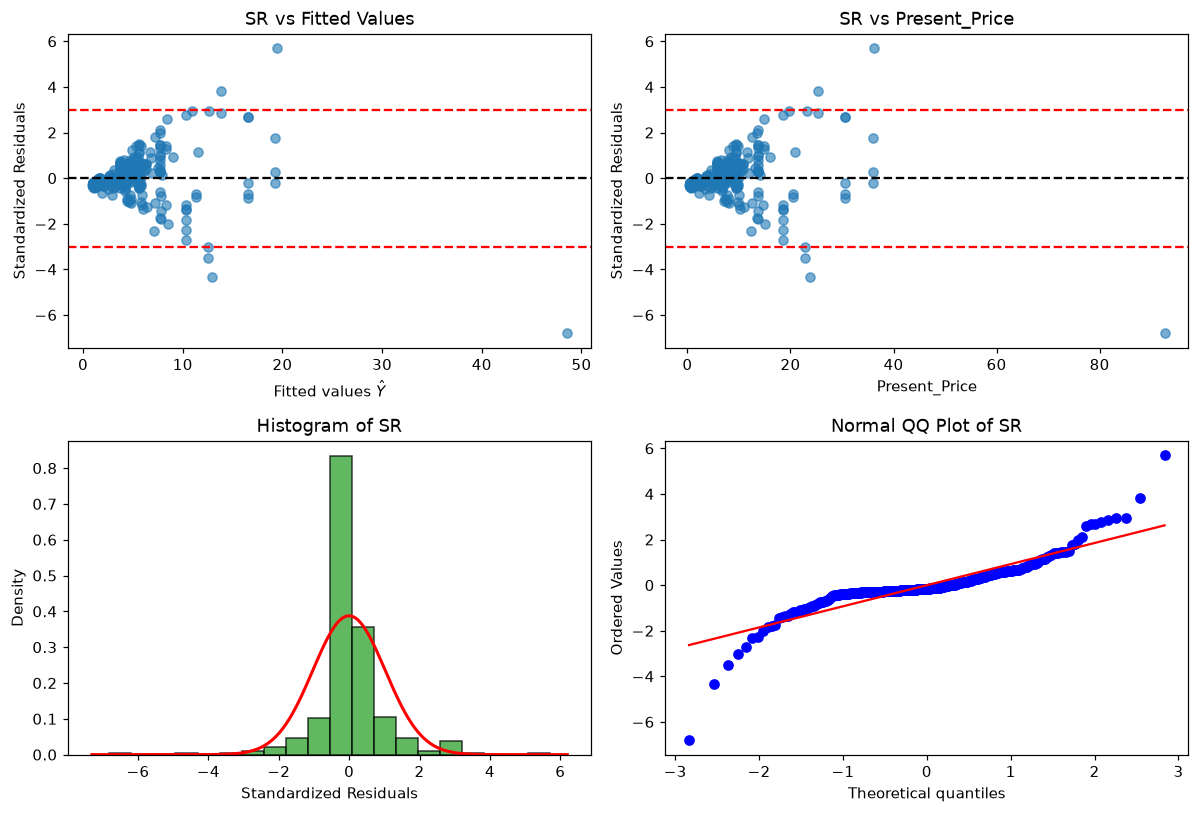

In [23]:
def plot_regression_diagnostics(fitted_model, x_series=None, x_name="X"):
    '''Plot the 4 standard ST1131 diagnostic plots + report outliers (|SR|>3) & Cook's D > 1.'''
    inf = fitted_model.get_influence()
    sr = inf.resid_studentized_internal
    cooks = inf.cooks_distance[0]
    yhat = fitted_model.fittedvalues

    out_idx = yhat.index[np.abs(sr) > 3].tolist()
    inf_idx = yhat.index[cooks > 1].tolist()
    print(f"SR range: [{sr.min():.2f}, {sr.max():.2f}] | Outliers (|SR| > 3): {len(out_idx)} -> indices {out_idx}")
    print(f"Max Cook's D: {cooks.max():.2f} | Influential points (Cook's D > 1): {len(inf_idx)} -> indices {inf_idx}")

    fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

    # (0,0) SR vs Fitted values
    axes[0, 0].scatter(yhat, sr, color="tab:blue", alpha=0.6)
    axes[0, 0].set(title="SR vs Fitted Values", xlabel=r"Fitted values $\hat{Y}$", ylabel="Standardized Residuals")

    # (0,1) SR vs X (if supplied) or Cook's Distance stem plot
    if x_series is not None:
        axes[0, 1].scatter(x_series, sr, color="tab:blue", alpha=0.6)
        axes[0, 1].set(title=f"SR vs {x_name}", xlabel=x_name, ylabel="Standardized Residuals")
        scatter_axes = [axes[0, 0], axes[0, 1]]
    else:
        axes[0, 1].stem(np.arange(len(cooks)), cooks)
        axes[0, 1].axhline(1, color="red", linestyle="--")
        axes[0, 1].set(title="Cook's Distance", xlabel="Observation Index", ylabel="Cook's D")
        scatter_axes = [axes[0, 0]]

    for ax in scatter_axes:
        ax.axhline(0, color="black", linestyle="--")
        ax.axhline(3, color="red", linestyle="--")
        ax.axhline(-3, color="red", linestyle="--")

    # (1,0) Histogram of SR + Normal curve
    axes[1, 0].hist(sr, bins=20, density=True, color="tab:green", alpha=0.75, edgecolor="black")
    xs = np.linspace(sr.min() - 0.5, sr.max() + 0.5, 300)
    axes[1, 0].plot(xs, norm.pdf(xs, loc=np.mean(sr), scale=np.std(sr, ddof=1)), color="red", lw=2)
    axes[1, 0].set(title="Histogram of SR", xlabel="Standardized Residuals", ylabel="Density")

    # (1,1) QQ Plot of SR
    probplot(sr, plot=axes[1, 1])
    axes[1, 1].set_title("Normal QQ Plot of SR")

    plt.tight_layout()
    plt.show()
    return sr, cooks

sr_1, cooks_1 = plot_regression_diagnostics(mdl1, cars["Present_Price"], x_name="Present_Price")

#### Removing Regression Outliers (`|SR| > 3`) & Influential Points (`Cook's D > 1`)
Because `df.drop(index=...)` returns a **new copy** by default, assigning it to a new variable (e.g. `cars_clean`) keeps the original `cars` DataFrame intact so you can refit and compare models safely:

In [24]:
# Inspect the flagged rows first
print("Influential rows (Cook's D > 1):")
print(cars[cooks_1 > 1][["Car_Name", "Present_Price", "Selling_Price"]])

# Way 1: Drop by specific row index(es) -> original `cars` is NOT modified
cars_no_86 = cars.drop(index=86)                         # single index (use index=[64, 86] for multiple)

# Way 2: Automatically drop using `cooks_1` or `sr_1` returned by plot_regression_diagnostics()
cars_no_inf  = cars.drop(index=cars.index[cooks_1 > 1])                        # drop influential points only
cars_no_out  = cars.drop(index=cars.index[np.abs(sr_1) > 3])                   # drop |SR| > 3 outliers only
cars_no_both = cars.drop(index=cars.index[(np.abs(sr_1) > 3) | (cooks_1 > 1)]) # drop both

# Refit model on the cleaned copy and compare slopes
mdl1_clean = smf.ols("Selling_Price ~ Present_Price", data=cars_no_inf).fit()
print(f"\nOriginal rows = {len(cars)}, Slope = {mdl1.params['Present_Price']:.4f}, R^2 = {mdl1.rsquared:.4f}")
print(f"Cleaned  rows = {len(cars_no_inf)}, Slope = {mdl1_clean.params['Present_Price']:.4f}, R^2 = {mdl1_clean.rsquared:.4f}")

Influential rows (Cook's D > 1):
        Car_Name  Present_Price  Selling_Price
86  land cruiser           92.6           35.0

Original rows = 301, Slope = 0.5168, R^2 = 0.7726
Cleaned  rows = 300, Slope = 0.5932, R^2 = 0.7819


### 9.3 Multiple Regression, Categorical Baselines, Interactions, Quadratics & Transformations

In [25]:
# 1. Multiple Regression + Custom Categorical Baseline ('Petrol' instead of alphabetical 'CNG')
mdl_fuel = smf.ols("Selling_Price ~ Present_Price + Kms_Driven + C(Fuel_Type, Treatment('Petrol'))", data=cars).fit()
print("Multiple Regression w/ Custom Baseline ('Petrol'):")
print(mdl_fuel.params.round(5))
print(f"Adjusted R^2: {mdl_fuel.rsquared_adj:.4f}\n")

# 2. Interaction Model (Present_Price * C(Transmission)) & Sensitivity to Influential Point (index 86)
mdl_int = smf.ols("Selling_Price ~ Present_Price * C(Transmission)", data=cars).fit()
p_int = mdl_int.params
print("Interaction Model Group Equations (Full Data):")
print(f"  Automatic (baseline): Y_hat = {p_int['Intercept']:.3f} + {p_int['Present_Price']:.3f} * Present_Price")
print(f"  Manual:               Y_hat = {p_int['Intercept'] + p_int['C(Transmission)[T.Manual]']:.3f} + "
      f"{p_int['Present_Price'] + p_int['Present_Price:C(Transmission)[T.Manual]']:.3f} * Present_Price")
print(f"  Interaction p-value (with index 86):    {mdl_int.pvalues['Present_Price:C(Transmission)[T.Manual]']:.3e}")

mdl_int_drop = smf.ols("Selling_Price ~ Present_Price * C(Transmission)", data=cars.drop(index=86)).fit()
print(f"  Interaction p-value (without index 86): {mdl_int_drop.pvalues['Present_Price:C(Transmission)[T.Manual]']:.4f} (no longer significant!)\n")

# 3. Quadratic Term I(X**2) & Response Transformations (sqrt(Y), log(Y))
mdl_quad = smf.ols("Selling_Price ~ Present_Price + I(Present_Price**2)", data=cars).fit()
mdl_sqrt = smf.ols("np.sqrt(Selling_Price) ~ Present_Price", data=cars).fit()
mdl_log  = smf.ols("np.log(Selling_Price) ~ Present_Price", data=cars).fit()

print(f"Quadratic Model Adj R^2 = {mdl_quad.rsquared_adj:.4f} (vs Simple Linear Adj R^2 = {mdl1.rsquared_adj:.4f})")
print(f"Sqrt-Response Fitted: sqrt(Selling_Price)_hat = {mdl_sqrt.params['Intercept']:.4f} + {mdl_sqrt.params['Present_Price']:.4f} * Present_Price")
print(f"Log-Response Fitted:  ln(Selling_Price)_hat   = {mdl_log.params['Intercept']:.4f} + {mdl_log.params['Present_Price']:.4f} * Present_Price")

Multiple Regression w/ Custom Baseline ('Petrol'):
Intercept                                      1.31409
C(Fuel_Type, Treatment('Petrol'))[T.CNG]      -0.35982
C(Fuel_Type, Treatment('Petrol'))[T.Diesel]    2.44157
Present_Price                                  0.48385
Kms_Driven                                    -0.00002
dtype: float64
Adjusted R^2: 0.8222

Interaction Model Group Equations (Full Data):
  Automatic (baseline): Y_hat = 0.029 + 0.613 * Present_Price
  Manual:               Y_hat = 0.994 + 0.455 * Present_Price
  Interaction p-value (with index 86):    2.043e-05
  Interaction p-value (without index 86): 0.2536 (no longer significant!)

Quadratic Model Adj R^2 = 0.8022 (vs Simple Linear Adj R^2 = 0.7718)
Sqrt-Response Fitted: sqrt(Selling_Price)_hat = 1.1172 + 0.1008 * Present_Price
Log-Response Fitted:  ln(Selling_Price)_hat   = 0.1192 + 0.1038 * Present_Price
